# Validating CoLoRe simulation for CMB lensing

- The CoLoRe simulation boxes were first generated by Laura Casas
- The notebook just uses the CMB lensing convergence $\kappa$ values of the boxes and validates it through the auto-spectrum.
- The kappa values can be found in `./data/...test_box/`, along with $C_{\ell}$ (and its associated errors), and a logarithmic rebinning run with `./scripts/rebin_cls_kk.py`, which is the one used in this notebook.
- The notebook also compares the two CoLoRe boxes in the folder.

In [179]:
import numpy as np
import matplotlib.pyplot as plt
import camb

import scipy
from scipy.integrate import quad
from scipy.constants import c
import sys
sys.path.append('../')

from py.rebinning import log_bin_cls  
import json

plt.rcParams.update({
    "text.usetex": True,
    "font.family": 'serif',
})

# Theory CMB lensing auto-spectrum $C_{\ell}^{\kappa \kappa}$

## setting up CAMB

In [180]:
# set the k and redshift range for the boltzmann solver
kmin, kmax = 1E-3, 100
zmin, zmax = 0, 1100
nz = 200
z_pk = zmin + np.exp(np.log(zmax - zmin + 1)*np.linspace(0, 1, nz)) - 1

# range of multipoles of the power spectrum to be studied
lmin = 2
lmax = 2500
ells = np.arange(lmin, lmax+1)

In [181]:
def load_cosmology(filename):
    with open(filename) as f:
        return json.load(f)

In [182]:
def get_camb_results(
    cosmo_dict,
    z_pk,
    kmax=100.0,
    lmax=2500,
    nonlinear=False,
    window=False,
):
    """
    Read a cosmological parameter dictionary, extract cosmological parameters,
    and build:

    1. CAMBparams instance
    2. CAMB results object

    Parameters
    ----------
    cosmo_dict : dict
        Dictionary containing cosmological parameters

    z_pk : list or None
        Redshifts for P(k) interpolator.
        If None, defaults to [0.0]

    kmax : float
        Maximum k [1/Mpc]

    lmax : integer
        Maximum multipole

    nonlinear : bool
        Whether to use nonlinear P(k)
    """

    # --------------------------------------------------
    # Convert to CAMB inputs
    # --------------------------------------------------

    H0 = 100.0 * cosmo_dict["h"]
    ombh2 = cosmo_dict["omega_B"] * cosmo_dict["h"]**2
    omch2 = (cosmo_dict["omega_M"] - cosmo_dict["omega_B"]) * cosmo_dict["h"]**2

    # --------------------------------------------------
    # Initial CAMB params
    # --------------------------------------------------

    pars = camb.CAMBparams()

    pars.set_cosmology(
        H0=H0,
        ombh2=ombh2,
        omch2=omch2,
    )

    pars.set_dark_energy(w=cosmo_dict["w"])
    pars.InitPower.set_params(
        ns=cosmo_dict["ns"],
        As=cosmo_dict["As"]
    )

    # --------------------------------------------------
    # Matter power settings
    # --------------------------------------------------

    pars.set_matter_power(
        redshifts=z_pk,
        kmax=kmax
    )

    if nonlinear:
        pars.NonLinear = camb.model.NonLinear_pk
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=2, nonlinear=True)
    else:
        pars.set_for_lmax(lmax=lmax, lens_potential_accuracy=2, nonlinear=False)

    if window:
        # 1. Use a dense grid but restricted range to keep memory light
        z_win = np.linspace(0, 12.0, 400)
        z_cut = cosmo_dict["z_max"]
        
        # 2. Smooth taper (Essential: hard steps often cause Fortran NaN crashes)
        w_z = 0.5 * (1 - np.tanh((z_win - z_cut) / 0.1))
        
        # 3. Use SplinedSourceWindow from sources
        wind = camb.sources.SplinedSourceWindow(source_type='lensing')
        wind.set_table(z=z_win, W=w_z)
        
        # 4. Attach as a list
        pars.SourceWindows = [wind]
        
        # 5. CRITICAL FLAGS FOR STABILITY
        pars.Want_Sources = True
        pars.SourceTerms.limber_windows = True  # Use Limber to avoid complex integrals
        pars.SourceTerms.counts_density = False # Turn off extra terms to save memory
        pars.SourceTerms.counts_redshift = False



    # Final results
    results = camb.get_results(pars)

    return results

## manual Limber integral

In [ ]:
def w_kappa(chi, z_chi, chi_source, cosmo_params):
    '''
    CMB lensing convergence kernel
    '''
    
    # scale factor at redshift of lensing structure
    a = 1.0 / (1.0 + z_chi)
    c_kms = c*1E-3

    # cosmological parameters
    H0, om = cosmo_params
    
    # prefactor of the kernel
    w_prefactor = (1.5) * (H0/c_kms)**2 * om * (chi_source - chi)/chi_source
    w_geom = (chi/a)
    
    return w_prefactor * w_geom

In [ ]:
def limber(chi, ell, chi_source,cosmo_params, pk_interp, results):
    '''
    CMB lensing auto-spectrum using Limber approximation
    '''

    # converting chi to redshift
    z_chi = results.redshift_at_comoving_radial_distance(chi)
    k = (ell + 0.5) / chi  
    kp = 0.31  # (1/Mpc) k pressure parameter scale used for smoothing the power spectrum according to the colore simulation resolution


    # kernel and pk interpolator, filtering out of extrapolation k and small k
    if 1e-4 < k < kmax:
        win = w_kappa(chi, z_chi, chi_source, cosmo_params)
        pk = pk_interp.P(z_chi, k, grid=False)
        smooth = np.exp(-(k/kp)**2)  # smoothing factor to avoid oscillations at high k 
        return (win**2 / chi**2) * pk * smooth
        
    else:
        return 0

In [185]:
def get_limber_cls(cosmo_params_filename):

    # get linear and non-linear matter power spectrum
    cosmo_dict = load_cosmology(cosmo_params_filename)
    z_max, z_out = cosmo_dict["z_max"], cosmo_dict["z_out"]

    results_lin = get_camb_results(
        cosmo_dict=cosmo_dict,
        z_pk=z_pk,
        kmax=kmax,
        lmax=lmax,
        nonlinear=False)
    results_nlin = get_camb_results(
        cosmo_dict=cosmo_dict,
        z_pk=z_pk,
        kmax=kmax,
        lmax=lmax,
        nonlinear=True)
    
    # comoving distance of the last scattering surface 
    z_star = results_lin.get_derived_params()['zstar']  # z_star doesn't match z_out until third box
    chi_star = results_lin.comoving_radial_distance(z_star)
    chi_max = results_lin.comoving_radial_distance(z_max)  # comoving distance of z_max

    # Hubble parameter and matter density for the kernel
    H0 = cosmo_dict["h"] * 100
    om = cosmo_dict["omega_M"]
    cosmo_params = (H0, om)

    # get the matter power spectrum interpolators for linear and non-linear cases
    pk_interp_lin = results_lin.get_matter_power_interpolator(nonlinear=False, 
                                                      hubble_units=False, 
                                                      k_hunit=False,  
                                                      var1='delta_tot', 
                                                      var2='delta_tot')
    pk_interp_nlin = results_nlin.get_matter_power_interpolator(nonlinear=True, 
                                                         hubble_units=False, 
                                                         k_hunit=False,  
                                                         var1='delta_tot', 
                                                         var2='delta_tot')
    
    #store the cls from linear and nonlinear limber approximation integration
    # redshift integration up to zmax
    cl_kk_lin_zs_zs = np.zeros(ells.shape)
    cl_kk_nlin_zs_zs = np.zeros(ells.shape)
    cl_kk_lin_zmax_zs = np.zeros(ells.shape)
    cl_kk_nlin_zmax_zs = np.zeros(ells.shape)
    cl_kk_lin_zmax_zmax = np.zeros(ells.shape)
    cl_kk_nlin_zmax_zmax = np.zeros(ells.shape)

    # manually integrate the limber approximation
    for i, ell in enumerate(ells):

        # integral up to redshift z_source, source plane at z_star
        chi_source = chi_star
        chi_cut = chi_star
        cl_kk_lin_zs_zs[i] = quad(limber, 0.001, chi_cut, args=(ell, chi_source, cosmo_params, pk_interp_lin, results_lin), epsabs=1E-10)[0]
        cl_kk_nlin_zs_zs[i] = quad(limber, 0.001, chi_cut, args=(ell, chi_source, cosmo_params, pk_interp_nlin, results_nlin), epsabs=1E-10)[0]
        
        # integral up to redshift z_max, source plane at z_star
        chi_source = chi_star
        chi_cut = chi_max
        cl_kk_lin_zmax_zs[i] = quad(limber, 0.001, chi_cut, args=(ell, chi_source, cosmo_params, pk_interp_lin, results_lin), epsabs=1E-10)[0]
        cl_kk_nlin_zmax_zs[i] = quad(limber, 0.001, chi_cut, args=(ell, chi_source, cosmo_params, pk_interp_nlin, results_nlin), epsabs=1E-10)[0]

        # integral up to redshift z_max, source plane at z_max, uncomment just for the first box
        #chi_source = chi_max
        #chi_cut = chi_max
        #cl_kk_lin_zmax_zmax[i] = quad(limber, 0.001, chi_max, args=(ell, chi_source, cosmo_params, pk_interp_lin, results_lin), epsabs=1E-10)[0]
        #cl_kk_nlin_zmax_zmax[i] = quad(limber, 0.001, chi_max, args=(ell, chi_source, cosmo_params, pk_interp_nlin, results_nlin), epsabs=1E-10)[0]

    return {
        'results_lin': results_lin,
        'results_nlin': results_nlin,
        'cl_kk_lin_zmax_zs': cl_kk_lin_zmax_zs,
        'cl_kk_nlin_zmax_zs': cl_kk_nlin_zmax_zs,
        'cl_kk_lin_zs_zs': cl_kk_lin_zs_zs,
        'cl_kk_nlin_zs_zs': cl_kk_nlin_zs_zs,
        'z_max': z_max,
        'z_out': z_out,
        'z_star': z_star,
        'chi_max': chi_max,
        'chi_star': chi_star,
    }


In [ ]:
# get the limber cls for the second and third boxes
box2 = get_limber_cls('../data/second_test_box/cosmo_params.json')
box3 = get_limber_cls('../data/third_test_box/cosmo_params.json')

# extract the relevant results for the second and third boxes
keys = ['results_lin', 'results_nlin', 'cl_kk_lin_zs_zs', 'cl_kk_nlin_zs_zs', 'cl_kk_lin_zmax_zs', 'cl_kk_nlin_zmax_zs', 'z_out', 'z_star']

results_lin_box2, results_nlin_box2, cl_kk_lin_zs_zs_box2, cl_kk_nlin_zs_zs_box2, cl_kk_lin_zmax_zs_box2, cl_kk_nlin_zmax_zs_box2, z_out_box2, z_star_box2 = [box2[k] for k in keys]
results_lin_box3, results_nlin_box3, cl_kk_lin_zs_zs_box3, cl_kk_nlin_zs_zs_box3, cl_kk_lin_zmax_zs_box3, cl_kk_nlin_zmax_zs_box3, z_out_box3, z_star_box3 = [box3[k] for k in keys]
z_max = box2['z_max']


Note: redshifts have been re-sorted (earliest first)
Note: redshifts have been re-sorted (earliest first)


## full sky (non-Limber) integral

In [187]:
def get_camb_cls(results, lmin=2, lmax=2500):
    '''
    Get the CAMB kappa power spectrum Cl^kappakappa from the CAMB results object
    '''
    camb_cls = results.get_lens_potential_cls(lmax=lmax, raw_cl=True)
    camb_cls = camb_cls[lmin:, 0]
    camb_cls = (ells * (ells + 1) / 2 )**2 * camb_cls  # Convert from C_ell^phiphi to C_ell^kappakappa

    return camb_cls # Extract the lensing potential auto-spectrum (phiphi)

In [ ]:
# get the CAMB cls for the second and third boxes
cl_kk_camb_lin_box2 = get_camb_cls(results_lin_box2, lmin, lmax)
cl_kk_camb_nlin_box2 = get_camb_cls(results_nlin_box2, lmin, lmax)
cl_kk_camb_lin_box3 = get_camb_cls(results_lin_box3, lmin, lmax)
cl_kk_camb_nlin_box3 = get_camb_cls(results_nlin_box3, lmin, lmax) 

# CoLoRe simulation auto-spectrum $C_{\ell}^{\kappa \kappa}$

In [189]:
def get_colore_cls(box_filename):
    '''
    Load the Colore kappa power spectrum from a text file
    '''

    # load the data from the .npz file
    data = np.load(box_filename)
    ells_colore, cl_kk_colore, err_tt = data['ells'], data['cls'], data['err']

    return ells_colore, cl_kk_colore, err_tt

In [190]:
ells_colore, cl_kk_colore_box1, err_tt_box1 = get_colore_cls('../data/first_test_box/cl_kk_log.npz')
ells_colore, cl_kk_colore_box2, err_tt_box2 = get_colore_cls('../data/second_test_box/cl_kk_log.npz')
ells_colore, cl_kk_colore_box3, err_tt_box3 = get_colore_cls('../data/third_test_box/cl_kk_log.npz')
nbins = ells_colore.size

# filter out NaN values which may arise from empty bins in the rebinning process
mask = np.isfinite(ells_colore)
ells_colore = ells_colore[mask]
cl_kk_colore_box1, err_tt_box1 = [array[mask] for array in [cl_kk_colore_box1, err_tt_box1]]
cl_kk_colore_box2, err_tt_box2 = [array[mask] for array in [cl_kk_colore_box2, err_tt_box2]]
cl_kk_colore_box3, err_tt_box3 = [array[mask] for array in [cl_kk_colore_box3, err_tt_box3]]

# determine the lmin and lmax from the Colore data to ensure consistent binning for residuals
lmin_colore = lmin
lmax_colore = np.load(f'../data/first_test_box/cl_kk.npz')['ells'].max()

# plotting

## latest CoLoRe box analysis and $\chi^2$ test

In [191]:
# rebin the CAMB linear and non-linear cls to match the number of bins in the Colore data for residuals
cl_kk_lin_zmax_zs_box2_rebin = log_bin_cls(ells, cl_kk_lin_zmax_zs_box2, nbins=nbins, ell_min=lmin_colore, ell_max=lmax_colore)[1]
cl_kk_lin_zmax_zs_box3_rebin = log_bin_cls(ells, cl_kk_lin_zmax_zs_box3, nbins=nbins, ell_min=lmin_colore, ell_max=lmax_colore)[1]

# filter out NaN values which may arise from empty bins in the rebinning process
cl_kk_lin_zmax_zs_box2_rebin = cl_kk_lin_zmax_zs_box2_rebin[mask]
cl_kk_lin_zmax_zs_box3_rebin = cl_kk_lin_zmax_zs_box3_rebin[mask]

In [192]:
def plot_cls_comparison(ells_colore, cl_kk_colore, err_tt, ells, cl_kk_lin, cl_kk_lin_rebin, z_out,z_star, box_label):

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 6), height_ratios=[2.5, 1], dpi=120, sharex=True)

    # compute the reduced chi-squared between the rebinned linear limber and the rebinned CoLoRe cls
    chi2 = np.sum((cl_kk_colore - cl_kk_lin_rebin)**2 / err_tt**2)
    chi2_nu = chi2 / (len(ells_colore))

    # plot the rebinned CoLoRe Cls with error bars
    ax1.errorbar(ells_colore, cl_kk_colore, yerr=err_tt, elinewidth=0.7, capsize=1.0, fmt='C0.', markersize=5.0, 
                 label=rf'CoLoRe_{box_label} $(z_{{\rm max}} = {z_max}, \ z_s={int(z_out)})$')
    ax1.scatter(0, 0 , s=0, label=rf'$\chi^2_\nu = {chi2_nu:.2f}$')

    # manual limber integration full redshift
    ax1.plot(ells, cl_kk_lin, c='C0', ls='-', label=rf'Limber_linear ($z_{{\rm cut}} = {z_max}, \ z_s={int(z_star)}$)')

    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.set_xlim(1.5, lmax)
    ax1.set_ylabel(r'$C_{L}^{\kappa \kappa}$')
    ax1.legend()

    # plot the relative error between the rebinned linear limber and the rebinned CoLoRe cls
    rel_error = (cl_kk_colore - cl_kk_lin_rebin) / cl_kk_lin_rebin
    rel_error_err = err_tt / cl_kk_lin_rebin

    # split the relative error plot into two panels for better visibility of low and high multipoles
    l_lim = 100

    # plot the relative error for low multipoles in the main panel
    ax2.errorbar(ells_colore[ells_colore < l_lim], rel_error[ells_colore < l_lim], 
                yerr=rel_error_err[ells_colore < l_lim], capsize=1.0, elinewidth=0.7, fmt='C0.', markersize=5.0)
    ax2.axhline(0, c='k', ls='--', lw=0.7)
    ax2.set_ylim(-1.0, 1.0)
    ax2.set_xscale('log')
    ax2.set_xlabel(r'$L$')
    ax2.set_ylabel(rf'rel. error $L<{l_lim}$')

    # plot the relative error for high multipoles in a separate panel
    ax3 = ax2.twinx()
    ax3.errorbar(ells_colore[ells_colore >= l_lim], rel_error[ells_colore >= l_lim], 
                yerr=rel_error_err[ells_colore >= l_lim], capsize=1.0, elinewidth=0.7, fmt='C1.', markersize=5.0)
    ax3.set_ylim(-0.2, 0.2)
    ax3.set_xscale('log')
    ax3.set_xlabel(r'$L$')
    ax3.set_ylabel(rf'rel. error $L\geq {l_lim}$')

    fig.suptitle('CMB lensing autospectrum: Theory vs. CoLoRe boxes', y=0.93)

    fig.savefig(f'plots/cls_kk_{box_label}.png', bbox_inches='tight')
    fig.savefig(f'plots/cls_kk_{box_label}.pdf', bbox_inches='tight')
    plt.show()

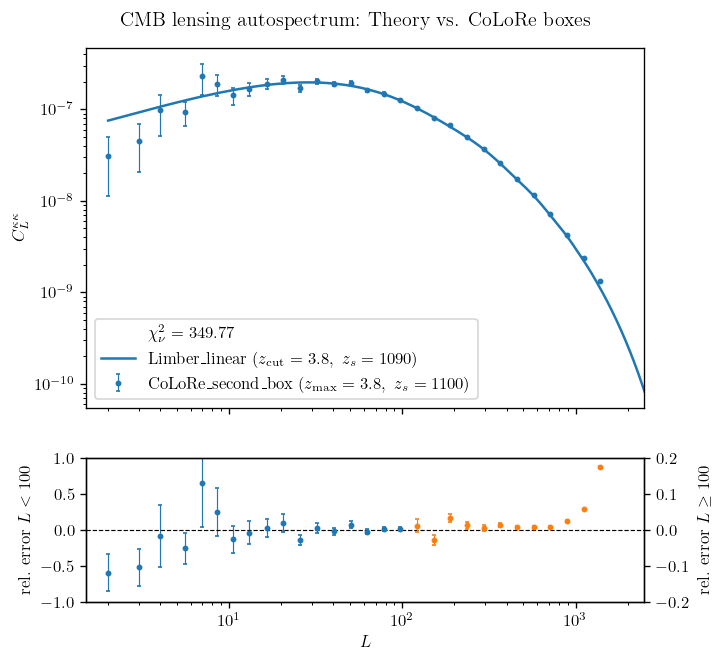

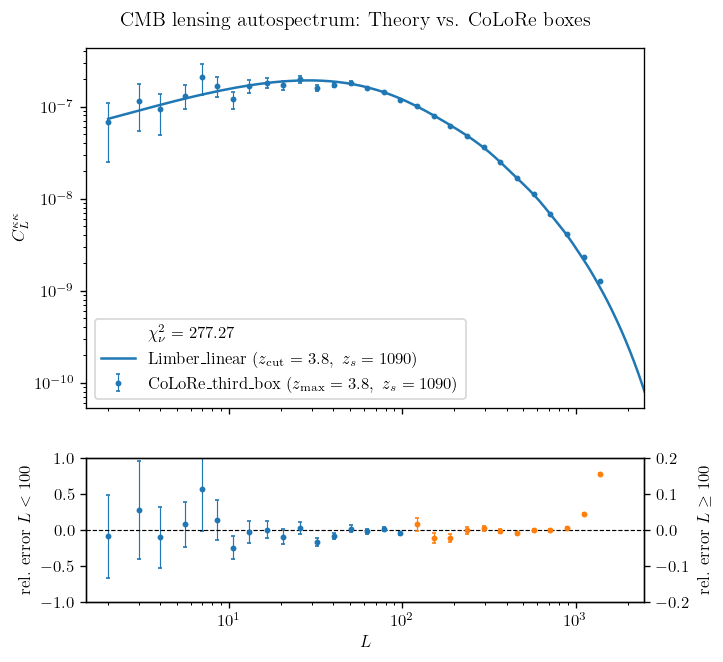

In [193]:
plot_cls_comparison(ells_colore, cl_kk_colore_box2, err_tt_box2, ells, cl_kk_lin_zmax_zs_box2, 
                    cl_kk_lin_zmax_zs_box2_rebin, z_out_box2, z_star_box2, box_label='second_box')
plot_cls_comparison(ells_colore, cl_kk_colore_box3, err_tt_box3, ells, cl_kk_lin_zmax_zs_box3, 
                    cl_kk_lin_zmax_zs_box3_rebin, z_out_box3, z_star_box3, box_label='third_box')  

In [194]:
def plot_cumulative_chi2(ells_colore, cl_kk_colore, err_tt, cl_kk_lin_rebin, box_label):

    # compute the cumulative chi-square and p-values for each multipole bin
    chi2_per_bin = ((cl_kk_colore - cl_kk_lin_rebin) / err_tt)**2
    cumulative_chi2 = np.nancumsum(chi2_per_bin)
    cumulative_dof = np.arange(1, len(cumulative_chi2) + 1)
    p_values = 1 - scipy.stats.chi2.cdf(cumulative_chi2, df=cumulative_dof)

    # Plotting the cumulative chi-square
    fig, ax1 = plt.subplots(figsize=(6, 4), dpi=120)
    ax2 = ax1.twinx()  # Create a second y-axis for p-values

    # Plot your cumulative chi-square
    ax1.plot(ells_colore, cumulative_chi2, marker='.', linestyle='-', color='C0', label=rf'Cumulative $\chi^2$ ({box_label})')
    ax2.plot(ells_colore, p_values, marker='.', linestyle='-', color='C1', label=r'Cumulative $p$-value', alpha=0.3)

    # Plot the expected theoretical baseline (Expected chi^2 = dof)
    ax1.plot(ells_colore, cumulative_dof, linestyle='--', color='black', label=r'Expected $\chi^2$ (Perfect Fit)')

    # Formatting the plot
    ax1.set_xscale('log')
    ax1.set_yscale('linear') # A log scale on the y-axis is highly recommended since the max value is ~8000
    ax1.set_ylim(0, 100)
    ax1.set_xlabel('$L$')
    ax1.set_ylabel(r'Cumulative $\chi^2$')
    ax2.set_ylabel(r'Cumulative $p$-value')
    ax1.set_title(r'Cumulative $\chi^2$ vs. Multipole $L$')
    ax1.legend(loc='upper left')
    ax2.legend(loc='upper right')

    fig.savefig(f'plots/cls_kk_{box_label}_cumulative_chi2.png', bbox_inches='tight')  
    fig.savefig(f'plots/cls_kk_{box_label}_cumulative_chi2.pdf', bbox_inches='tight')  

    plt.show()

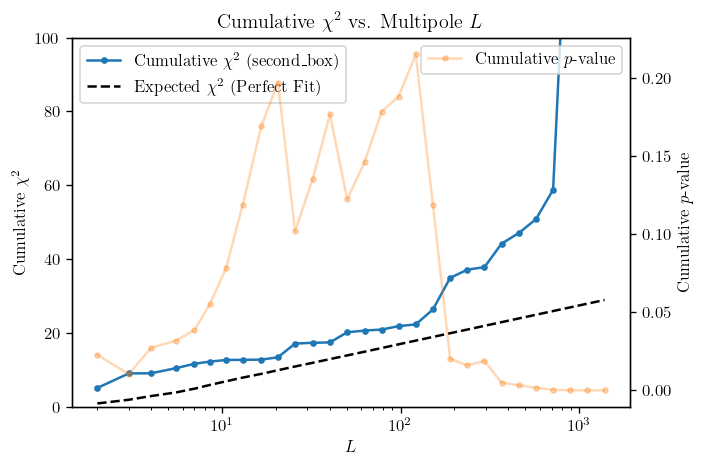

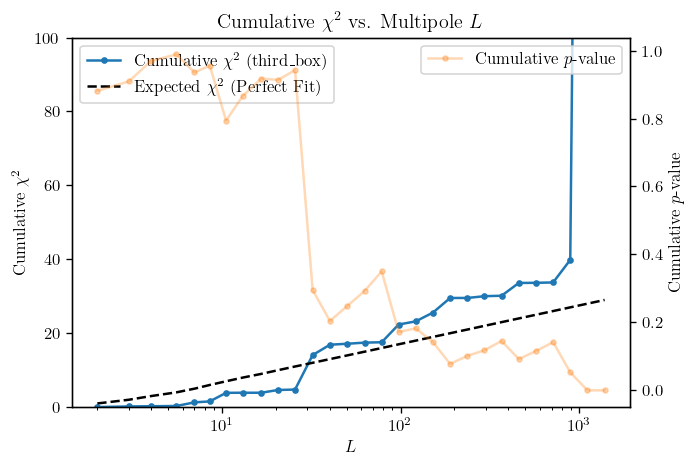

In [195]:
plot_cumulative_chi2(ells_colore, cl_kk_colore_box2, err_tt_box2, cl_kk_lin_zmax_zs_box2_rebin, box_label='second_box')
plot_cumulative_chi2(ells_colore, cl_kk_colore_box3, err_tt_box3, cl_kk_lin_zmax_zs_box3_rebin, box_label='third_box')

## comparing CoLoRe boxes
source plane changes between them

In [196]:
def plot_compare_boxes(ells_colore, cl_kk_colore_box1, cl_kk_colore_box2, err_tt_1, err_tt_2, 
                       ells, cl_kk_lin1, cl_kk_lin2, cl_kk_lin1_rebin, cl_kk_lin2_rebin,
                       z_max, z_out_box1, z_out_box2, z_star_box1, z_star_box2, box_label1, box_label2):

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 6), height_ratios=[3, 1], dpi=120, sharex=True)

    # plot the rebinned CoLoRe Cls with error bars
    ax1.errorbar(ells_colore, cl_kk_colore_box1, yerr=err_tt_1, elinewidth=0.7, capsize=1.0, fmt='C1.', markersize=5.0, label=rf'CoLoRe_{box_label1} ($z_{{\rm max}} = {z_max}, \ z_s={int(z_out_box1)}$)')
    ax1.errorbar(ells_colore, cl_kk_colore_box2, yerr=err_tt_2, elinewidth=0.7, capsize=1.0, fmt='C0.', markersize=5.0, label=rf'CoLoRe_{box_label2} ($z_{{\rm max}} = {z_max}, \ z_s={int(z_out_box2)}$)')

    # manual limber integration full redshift
    ax1.plot(ells, cl_kk_lin1, c='C1', ls='-', label=rf'Limber_linear ($z_{{\rm cut}} = {z_max}, \ z_s={int(z_star_box1)}$)')
    ax1.plot(ells, cl_kk_lin2, c='C0', ls='-', label=rf'Limber_linear ($z_{{\rm cut}} = {z_max}, \ z_s={int(z_star_box2)}$)')

    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.set_xlim(1.5, lmax)
    ax1.set_ylabel(r'$C_{L}^{\kappa \kappa}$')
    ax1.legend()

    # plot the relative error between the rebinned linear limber and the rebinned CoLoRe cls
    ax2.errorbar(ells_colore, (cl_kk_colore_box1-cl_kk_lin1_rebin)/cl_kk_lin1_rebin, 
                yerr=err_tt_1/cl_kk_lin1_rebin, capsize=1.5, elinewidth=0.7, fmt='C0-', markersize=5.0)
    ax2.errorbar(ells_colore, (cl_kk_colore_box2-cl_kk_lin2_rebin)/cl_kk_lin2_rebin, 
                yerr=err_tt_2/cl_kk_lin2_rebin, capsize=1.5, elinewidth=0.7, fmt='C1-', markersize=5.0)
    ax2.axhline(0, c='k', ls='--', lw=0.7)
    ax2.set_xscale('log')
    ax2.set_xlabel(r'$L$')
    ax2.set_ylabel('relative error')
    ax2.set_ylim(-1.0, 1.0)

    fig.suptitle('CMB lensing autospectrum: CoLoRe boxes comparison', y=0.93)

    fig.savefig(f'plots/cls_kk_boxes_comparison.png', bbox_inches='tight')
    fig.savefig(f'plots/cls_kk_boxes_comparison.pdf', bbox_inches='tight')
    plt.show()

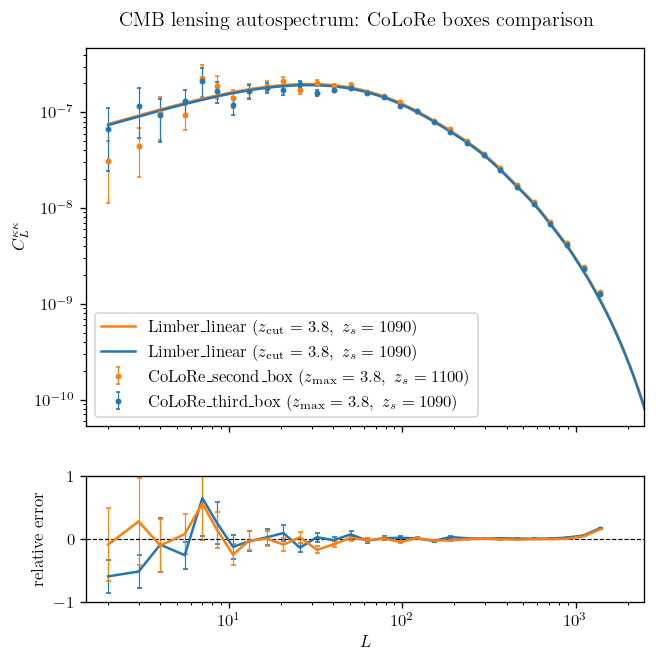

In [197]:
plot_compare_boxes(ells_colore, cl_kk_colore_box2, cl_kk_colore_box3, err_tt_box2, err_tt_box3, 
                   ells, cl_kk_lin_zmax_zs_box2, cl_kk_lin_zmax_zs_box3, cl_kk_lin_zmax_zs_box2_rebin, cl_kk_lin_zmax_zs_box3_rebin,
                   z_max, z_out_box2, z_out_box3, z_star_box2, z_star_box3, box_label1='second_box', box_label2='third_box')

## comparing theory

In [198]:
def plot_theory_cls(ells, cl_kk_lin_zs_zs, cl_kk_nlin_zs_zs, cl_kk_camb_lin, cl_kk_camb_nlin, z_star):
    '''
    Plot the theoretical CMB lensing auto-spectrum from manual Limber integration and CAMB fullsky integration 
    for both linear and non-linear matter power spectra
    '''

    plt.figure(figsize=(6, 4), dpi=120)

    # manual limber integration full redshift
    plt.loglog(ells, cl_kk_lin_zs_zs, c='C0', ls='-', label=rf'Limber_lin ($z_{{\rm cut}} = z_s={int(z_star)}$)')
    plt.loglog(ells, cl_kk_nlin_zs_zs, c='C0', ls='--', label=rf'Limber_nonlin ($z_{{\rm cut}} = z_s={int(z_star)}$)')


    # full sky integration full redshift
    plt.loglog(ells, cl_kk_camb_lin, c='C1', ls='-', label=rf'nonLimber_lin ($z_{{\rm cut}} = z_s={int(z_star)}$)')
    plt.loglog(ells, cl_kk_camb_nlin, c='C1', ls='--', label=rf'nonLimber_nonlin ($z_{{\rm cut}} = z_s={int(z_star)}$)')

    plt.xlim(1.5, lmax)
    plt.ylim(8e-11, 4e-7)
    plt.xlabel(r'$L$')
    plt.ylabel(r'$C_{L}^{\kappa \kappa}$')

    plt.title('CMB lensing autospectrum: limber/non-Limber, linear/non-linear', y=1.05)
    plt.legend()

    plt.savefig(f'plots/cls_kk_theory_comparison.png', bbox_inches='tight')
    plt.savefig(f'plots/cls_kk_theory_comparison.pdf', bbox_inches='tight')
    plt.show()

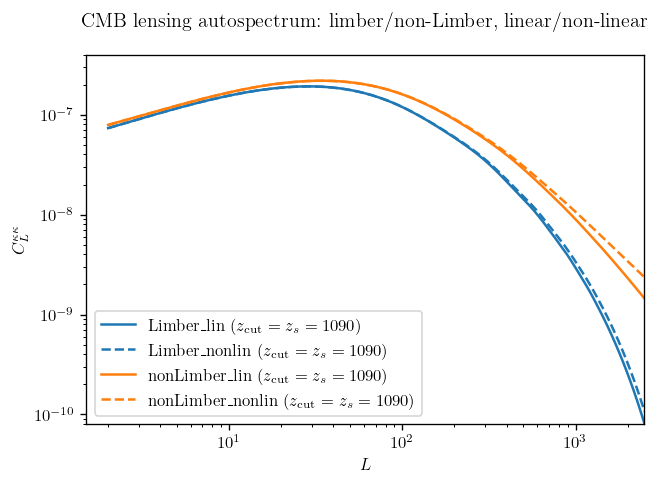

In [199]:
plot_theory_cls(ells, cl_kk_lin_zmax_zs_box3, cl_kk_nlin_zmax_zs_box3, cl_kk_camb_lin_box3, cl_kk_camb_nlin_box3, z_star_box3)